# Training Model

In [1]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

# Find project root
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Load dataset
df = pd.read_csv(
    PROJECT_ROOT / "data" / "raw" / "ai4i2020.csv"
)

FEATURES = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

TARGET = "Machine failure"

X = df[FEATURES].copy()
y = df[TARGET].copy()

# Encode categorical feature
X = pd.get_dummies(
    X,
    columns=["Type"],
    dtype=int
)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Training cell ready.")

X_train: (8000, 8)
X_test: (2000, 8)
Training cell ready.


In [3]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt

model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="aucpr",
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=1,
    random_state=42,
    n_jobs=-1,
)

In [4]:
# Rename columns to XGBoost-compatible names
column_mapping = {
    "Air temperature [K]": "air_temperature",
    "Process temperature [K]": "process_temperature",
    "Rotational speed [rpm]": "rotational_speed",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
}

X_train = X_train.rename(columns=column_mapping)
X_test = X_test.rename(columns=column_mapping)

print("Training columns:")
print(X_train.columns.tolist())

Training columns:
['air_temperature', 'process_temperature', 'rotational_speed', 'torque', 'tool_wear', 'Type_H', 'Type_L', 'Type_M']


Baseline XGBoost Results
-----------------------------------
Accuracy:  0.9850
Precision: 0.8958
Recall:    0.6324
F1-score:  0.7414
PR-AUC:    0.8282

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.90      0.63      0.74        68

    accuracy                           0.98      2000
   macro avg       0.94      0.81      0.87      2000
weighted avg       0.98      0.98      0.98      2000



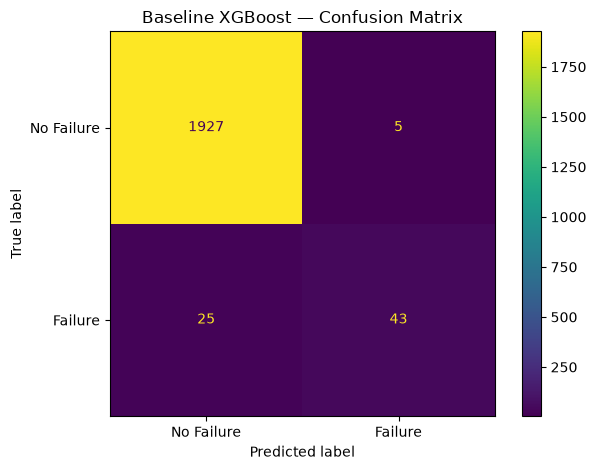

In [7]:


model.fit(X_train, y_train)

# Predictions using the default 0.5 threshold
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Baseline XGBoost Results")
print("-" * 35)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, y_prob):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Failure", "Failure"],
    values_format="d",
)
plt.title("Baseline XGBoost — Confusion Matrix")
plt.tight_layout()
plt.show()

## Optimising classification threshold

In [6]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

results = []

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred_threshold, labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "False Alarms": fp,
        "Missed Failures": fn,
        "Detected Failures": tp,
    })

threshold_results = pd.DataFrame(results)
threshold_results.round(3)

,Threshold,Precision,Recall,F1-score,False Alarms,Missed Failures,Detected Failures
0,0.1,0.487,0.838,0.616,60,11,57
1,0.2,0.691,0.824,0.752,25,12,56
2,0.3,0.754,0.765,0.759,17,16,52
3,0.4,0.828,0.706,0.762,10,20,48
4,0.5,0.896,0.632,0.741,5,25,43
5,0.6,0.927,0.559,0.697,3,30,38
